# Is the mechanistic latency model functioning?

**Model under test.** A team's latency is predicted as the sum, over the
instructions found in its disassembly, of the CV32E40X manual's cycle cost for each:

$$\widehat{L} = \sum_{\text{op}} \text{cost}(\text{op}) \times \text{count}(\text{op})$$

`cost` comes from `analysis/disassembler.py` (`INSTRUCTION_LATENCY`), transcribed
from the OpenHW CV32E40X user manual, *Pipeline Details* -> "Cycle Counts Per
Instruction Type".

**The property every section leans on.** The manual's hazard penalties are pairwise
effects that the table leaves out, so the sum is a *stall-free floor*: it should
never exceed the measurement. The two ways of being wrong then have different,
non-overlapping causes:

| Observation | Possible causes | Impossible causes |
|---|---|---|
| estimate **>** measured (floor violated) | the sum counts instructions that did not run; or an instruction is priced too high | stalls, probe overhead, uncounted callee code |
| estimate **<** measured | stalls; probe overhead; code that ran outside the team's own slice (a callee) | skipped code, over-priced instructions |

**Why two databases.** The same TPGs were compiled twice. In the `inline` build the
library functions (`fixedpt_exp_wdiv32`, `protected_fixedpt_div_32`, ...) are
inlined into each team; in the `noipa` build they stay calls. The code attributed to
a team, and with it the number of branches the team contains, is therefore
completely different between the two, while the computation is the same. Each
team-level hypothesis below is tested on both builds, and section 2 measures the
difference directly.

**How each section is written.** A section opens with the *question*, the
*hypothesis*, the *test*, and what the output looks like *if the hypothesis is
true and if it is false*. The code cell then ends with a line starting `>>>` that
states the verdict with its numbers, computed from whatever databases are
configured. Nothing in the prose depends on numbers that go stale when the
database changes; the summary table at the end is printed by code.

| # | Hypothesis | Section |
|---|---|---|
| H1 | The build changes where a team's code is, not what the core executes | 2 |
| H2 | With no control flow, the estimate is a floor and tracks the measurement | 4 |
| H3 | Branches inside a team make the estimate count code that did not run | 5 |
| H3b | That over-count comes from inlined library bodies, not the TPG's own operations | 5 |
| H3c | The over-estimate is only `div` being priced at its 35-cycle worst case | 5 |
| H4 | A team that calls a function is under-estimated by the callee's body | 6 |
| H5 | Instrumenting the teams adds a real, per-team cost | 7 |
| H6 | The per-team constant of H2's fit is that probe cost | 7 |
| H7 | The proportional gap above the floor is the manual's load-use penalty | 8 |
| H8 | The manual's per-instruction costs can be recovered from the data | 9 |

In [4]:
# --- Configuration -----------------------------------------------------------
# The same TPGs compiled two ways. Every team-level section runs on each entry
# and reports them side by side. One entry is enough: paired tests then skip.
BUILDS = {
    "inline": "db_fixedpt_iset32_inline",   # library functions inlined into the teams
    "noipa":  "db_fixedpt_iset32_noipa",    # library functions kept as calls (jal)
}
PRIMARY = "noipa"    # build used where one is enough (sections 7-9)
UARCH   = "cv32e40x_im1_zba_zbb"

import sys, os
from collections import Counter
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt

# Find the project root (the directory holding classes/) by walking up, so the
# notebook works whatever directory the kernel was started in.
ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "classes")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.chdir(ROOT)                      # so the database paths resolve relative to the repo

from classes.database import Database
from analysis.disassembler import Disassembler, INSTRUCTION_LATENCY
from analysis.analyzer import FeaturesAnalyzer

DBS = {name: Database.load(path) for name, path in BUILDS.items()}
for name, db in DBS.items():
    print(f"{name:<8} {BUILDS[name]:<34} {len(db.tpgs)} TPGs | uarchs: {list(db.uarchs)}")

[Database] Loaded from db_fixedpt_iset32_inline  (161 TPGs, 2 ISAs, 2 uarchs)
[Database] Loaded from db_fixedpt_iset32_noipa  (161 TPGs, 2 ISAs, 2 uarchs)
inline   db_fixedpt_iset32_inline           161 TPGs | uarchs: ['cv32e40x_im1_zba_zbb', 'cv32e40x_im2_zba_zbb']
noipa    db_fixedpt_iset32_noipa            161 TPGs | uarchs: ['cv32e40x_im1_zba_zbb', 'cv32e40x_im2_zba_zbb']


In [5]:
# --- Plot style, fit helper, verdict registry --------------------------------
# Categorical slots 1-3 of the validated default palette, one per team class.
# Scatter plots need every pair of colours to be separable, and only the first
# three slots are, so the analysis never uses a fourth.
C_STRAIGHT = "#2a78d6"   # slot 1, blue
C_BRANCH   = "#eb6834"   # slot 2, orange
C_CALL     = "#1baf7a"   # slot 3, aqua
INK        = "#3d3d3a"
MUTED      = "#8a8a80"

CLASSES     = ("straight", "branch", "call")
CLASS_COLOR = {"straight": C_STRAIGHT, "branch": C_BRANCH, "call": C_CALL}
CLASS_LABEL = {"straight": "straight-line", "branch": "branches, no call", "call": "calls a function"}

plt.rcParams.update({
    "figure.figsize": (7.5, 4.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e6e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "font.size": 9, "legend.frameon": False,
})

@dataclass
class Fit:
    '''An ordinary least-squares fit, with the numbers that matter printed.'''
    beta: np.ndarray; names: list; r2: float; mae: float
    pred: np.ndarray; cond: float; n: int

    def __repr__(self):
        terms = "  ".join(f"{nm}={b:+.3f}" for nm, b in zip(self.names, self.beta[:-1]))
        warn = "   [!] collinear, read coefficients with care" if self.cond > 30 else ""
        return (f"n={self.n}  {terms}  const={self.beta[-1]:+.2f}"
                f"   R2={self.r2:.4f}  MAE={self.mae:.2f} cyc{warn}")

def ols(X, y, names=None):
    '''Least squares of y on the columns of X plus an intercept.'''
    X = np.asarray(X, float)
    if X.ndim == 1: X = X[:, None]
    y = np.asarray(y, float)
    A = np.hstack([X, np.ones((len(y), 1))])
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    pred = A @ beta
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    names = names or [f"x{i}" for i in range(X.shape[1])]
    return Fit(beta, names, r2, float(np.abs(y - pred).mean()), pred,
               float(np.linalg.cond(A)), len(y))

VERDICTS = []
def verdict(h, scope, ok, numbers):
    '''Record and print the outcome of one hypothesis test (None = not testable).'''
    status = {True: "HOLDS", False: "REJECTED", None: "NOT TESTABLE"}[ok]
    VERDICTS[:] = [v for v in VERDICTS if v[:2] != (h, scope)]   # re-running replaces
    VERDICTS.append((h, scope, status, numbers))
    print(f">>> {h} [{scope}]: {status} -- {numbers}")
print("helpers ready")

helpers ready


## 1. How a team is classified

**What this section does.** It defines the three classes every later section is
split by, and shows how many teams of each build fall in each. It tests nothing;
it makes the split explicit so the tests can be read.

A team is the code between its entry and its exit in the binary (its *slice*). It
belongs to exactly one class, decided from the mnemonics in that slice:

| Class | Rule | What it means for a sum over static instructions |
|---|---|---|
| **straight-line** | no control-flow instruction | every instruction in the slice runs once: static count = executed count |
| **branches, no call** | at least one branch or jump, no call | some instructions in the slice may be skipped: static count >= executed count |
| **calls a function** | at least one `jal`/`jalr` to a function | code runs *outside* the slice: static count misses the callee's body |

Calls take precedence over branches: a team with both is a call team.

The first cell builds one row per measured team of each build. The second lists the
operations of each build with their table cost, so the content of the two builds can
be compared line by line.

In [6]:
BRANCHES = {
    # RV32I conditional branches
    "beq", "bne", "blt", "bge", "bltu", "bgeu",
    # branch pseudo-instructions objdump prints instead of the above
    "beqz", "bnez", "blez", "bgez", "bltz", "bgtz", "bgt", "ble", "bgtu", "bleu",
    # unconditional jumps that stay in the code being executed
    "j", "jr", "ret",
}
CALLS  = {"jal", "jalr", "call", "tail"}       # objdump prints a call as jal <callee>
DIVS   = {"div", "divu", "rem", "remu"}
LOADS  = {"lw", "lh", "lb", "lhu", "lbu"}
STORES = {"sw", "sh", "sb"}
MULH   = {"mulh", "mulhu", "mulhsu"}

def mnem(op):
    '''"jal_fixedpt_cos" -> "jal": the mnemonic of an operation name.'''
    return op.lower().split("_")[0]

def team_class(ops):
    m = {mnem(op) for op in ops}
    if m & CALLS:    return "call"
    if m & BRANCHES: return "branch"
    return "straight"

@dataclass
class TeamRow:
    tpg: str; team_id: int; ops: Counter; n: int
    meas: float; stddev: float; nruns: int
    cls: str; load_use: int; alu_haz: int

class Build:
    '''The measured teams of one database: rows, plus arrays parallel to them.'''
    def __init__(self, name, db):
        self.name, self.db, self.rows = name, db, []
        for tpg, tid, ct, m in db.get_measurements_for_uarch(UARCH):
            ins = ct.instructions or []
            if not ins:
                continue                  # a few teams have no parsed instructions
            # Distance-1 RAW hazards, split by whether the producer was a load: the
            # manual charges +1 for a load-use hazard and nothing for an ALU-ALU one.
            h = FeaturesAnalyzer._raw_hazard_counts(ins, max_distance=1)
            lu = sum(v for (_d, p, _c), v in h.items() if p.split("_")[0] in LOADS)
            ops = Counter(i.operation for i in ins)
            self.rows.append(TeamRow(
                tpg=tpg.name, team_id=tid, ops=ops, n=len(ins),
                meas=m.latency, stddev=m.stddev, nruns=m.nb_measurements,
                cls=team_class(ops), load_use=lu, alu_haz=sum(h.values()) - lu))
        self.keys = [(r.tpg, r.team_id) for r in self.rows]
        self.meas = np.array([r.meas for r in self.rows], float)
        self.nins = np.array([r.n for r in self.rows], float)
        self.lu   = np.array([r.load_use for r in self.rows], float)
        self.cls  = np.array([r.cls for r in self.rows])

    def count(self, group):
        '''Per team, how many instructions have their mnemonic in `group`.'''
        return np.array([sum(c for op, c in r.ops.items() if mnem(op) in group)
                         for r in self.rows], float)

B = {name: Build(name, db) for name, db in DBS.items()}
P = B[PRIMARY]
S = B["inline"]

print(f"{'build':<8}{'class':<20}{'teams':>7}{'share':>8}{'instrs (median)':>18}{'measured (median)':>20}")
print("-" * 81)
for b in B.values():
    for c in CLASSES:
        m = b.cls == c
        if m.sum():
            print(f"{b.name:<8}{CLASS_LABEL[c]:<20}{m.sum():>7}{100*m.mean():>7.1f}%"
                  f"{np.median(b.nins[m]):>18.0f}{np.median(b.meas[m]):>20.1f}")
    cv = np.array([r.stddev / r.meas * 100 if r.meas else 0 for r in b.rows])
    print(f"{'':<8}measurement noise: median CV {np.median(cv):.2f}%, p90 {np.percentile(cv, 90):.2f}%"
          f", median runs/team {np.median([r.nruns for r in b.rows]):.0f}\n")

build   class                 teams   share   instrs (median)   measured (median)
---------------------------------------------------------------------------------
inline  straight-line          2028   61.9%                14                26.0
inline  branches, no call      1232   37.6%               115                76.0
inline  calls a function         15    0.5%               116               161.0
        measurement noise: median CV 0.00%, p90 2.20%, median runs/team 10

noipa   straight-line          1996   60.7%                14                26.0
noipa   branches, no call       303    9.2%                16                25.0
noipa   calls a function        987   30.0%                20               132.0
        measurement noise: median CV 0.00%, p90 2.16%, median runs/team 10



In [7]:
# Operations of each build: everything that is control flow, a divide, or priced
# above one cycle, plus the ten most frequent operations of each build.
ops_seen = {name: sum((r.ops for r in b.rows), Counter()) for name, b in B.items()}
show = {op for c in ops_seen.values() for op, _ in c.most_common(10)}
show |= {op for c in ops_seen.values() for op in c
         if mnem(op) in BRANCHES | CALLS | DIVS or Disassembler.operation_latency(op) != 1}

def kind(op):
    m = mnem(op)
    return "call" if m in CALLS else "branch" if m in BRANCHES else ""

print(f"{'operation':<32}{'cost':>5}" + "".join(f"{n:>10}" for n in B) + "   class")
print("-" * (40 + 10 * len(B) + 6))
for op in sorted(show, key=lambda o: -sum(c[o] for c in ops_seen.values())):
    print(f"{op:<32}{Disassembler.operation_latency(op):>5}"
          + "".join(f"{ops_seen[n][op]:>10}" for n in B) + f"   {kind(op)}")
print("\nstatic instructions in total: "
      + "   ".join(f"{n} {sum(c.values())}" for n, c in ops_seen.items()))

operation                        cost    inline     noipa   class
------------------------------------------------------------------
add                                 1     35430      9207   
lw                                  1     17349     17633   
mul                                 1     26448      5348   
sw                                  1     12918     12369   
srai                                1     16075      3226   
slli                                1     15183      2027   
srli                                1     13339      1814   
lui                                 1     13736         0   
mulhu                               4      9939      1814   
addi                                1      9456        11   
sub                                 1      6096      2865   
max                                 1      3115      2276   
bltz                                1      2143         0   branch
blt                                 1      1825         3   branch
d

## 2. What the build does to a team

**Question.** The two builds compile the same TPGs. Do they describe the same
teams, and if so, what actually differs between them?

**Hypothesis H1.** *The build changes where a team's code is, not what the core executes.* Inlining copies a library function's body into the team's slice; `noipa`
leaves a `jal` there and keeps the body elsewhere. The work done is the same.

**Test.** Pair each team across the two builds by (TPG, team id). For every
transition "class in the first build -> class in the second", compare the static
instruction count and the measured latency.

**If H1 is true:** the static instruction count differs a lot for teams that use
library functions, while the measured latency of a pair is nearly equal (a call
adds a few cycles of jump and return). **If false:** measured latencies differ as
much as the code does, and the two builds cannot be compared team by team.

The criterion printed at the end: at least 90% of paired teams have measured
latencies within 10% or 10 cycles of each other.

In [8]:
PAIR = None
if len(B) < 2:
    verdict("H1", "paired", None, "only one build configured")
else:
    a, b = list(B.values())[:2]
    ib = {k: i for i, k in enumerate(b.keys)}
    pa = np.array([i for i, k in enumerate(a.keys) if k in ib], int)
    pb = np.array([ib[a.keys[i]] for i in pa], int)
    print(f"teams measured: {a.name} {len(a.rows)}, {b.name} {len(b.rows)}, in both {len(pa)}\n")
    if len(pa) < 30:
        verdict("H1", "paired", None, "the two databases share too few teams to pair")
    else:
        PAIR = dict(a=a, b=b, pa=pa, pb=pb)
        trans = np.array([f"{x} -> {y}" for x, y in zip(a.cls[pa], b.cls[pb])])
        d = b.meas[pb] - a.meas[pa]
        print(f"{'class ' + a.name + ' -> ' + b.name:<24}{'teams':>6}"
              f"{'instrs (median)':>18}{'measured (median)':>20}{'difference: median [p10, p90]':>32}")
        print("-" * 100)
        for t, cnt in Counter(trans).most_common():
            m = trans == t
            print(f"{t:<24}{cnt:>6}"
                  f"{np.median(a.nins[pa][m]):>10.0f} -> {np.median(b.nins[pb][m]):<4.0f}"
                  f"{np.median(a.meas[pa][m]):>12.1f} -> {np.median(b.meas[pb][m]):<6.1f}"
                  f"{np.median(d[m]):>+12.1f} [{np.percentile(d[m], 10):+.1f}, {np.percentile(d[m], 90):+.1f}]")

        moved = a.cls[pa] != b.cls[pb]
        close = (np.abs(d) <= 10) | (np.abs(d) <= 0.10 * a.meas[pa])
        size_ratio = np.median(a.nins[pa][moved] / b.nins[pb][moved]) if moved.any() else 1.0
        print(f"\nteams whose class changes with the build : {moved.sum()} ({100*moved.mean():.0f}%)")
        print(f"  their static size, {a.name} / {b.name}        : median {size_ratio:.1f}x")
        print(f"  their measured latency, {b.name} - {a.name}   : median {np.median(d[moved]):+.1f} cycles")
        print(f"teams whose class does not change        : measured difference median "
              f"{np.median(d[~moved]):+.1f}, max |diff| {np.abs(d[~moved]).max():.1f} cycles")
        far = ~close
        if far.any():
            print(f"\nthe {far.sum()} pairs further apart than 10% and 10 cycles, by transition: "
                  + ", ".join(f"{t} ({c})" for t, c in Counter(trans[far]).most_common()))
        print()
        verdict("H1", "paired", close.mean() >= 0.90,
                f"{100*close.mean():.1f}% of {len(pa)} pairs measure the same within 10% or 10 cycles "
                f"(r = {np.corrcoef(a.meas[pa], b.meas[pb])[0,1]:.3f}), while the static size of the "
                f"{moved.sum()} class-changing teams differs {size_ratio:.1f}x")

teams measured: inline 3275, noipa 3286, in both 3275

class inline -> noipa    teams   instrs (median)   measured (median)   difference: median [p10, p90]
----------------------------------------------------------------------------------------------------
straight -> straight      1993        14 -> 14          26.0 -> 26.0          +0.0 [+0.0, +0.0]
branch -> call             927       141 -> 20         117.0 -> 132.0         +7.0 [+2.0, +49.0]
branch -> branch           303        16 -> 16          25.0 -> 25.0          +0.0 [+0.0, +0.0]
straight -> call            35        13 -> 16          24.0 -> 71.0         +43.0 [+10.4, +111.6]
call -> call                15       116 -> 16         161.0 -> 164.0         +7.0 [+0.0, +53.6]
branch -> straight           2        58 -> 15         108.0 -> 28.0         -80.0 [-120.8, -39.2]

teams whose class changes with the build : 964 (29%)
  their static size, inline / noipa        : median 7.0x
  their measured latency, noipa - inline   : med

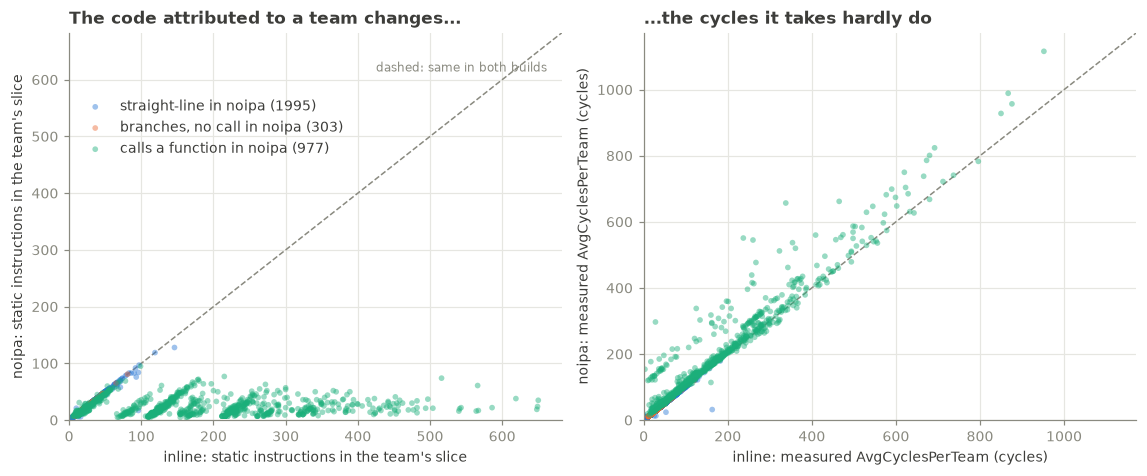

In [9]:
if PAIR:
    a, b, pa, pb = PAIR["a"], PAIR["b"], PAIR["pa"], PAIR["pb"]
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
    panels = ((a.nins[pa], b.nins[pb], "static instructions in the team's slice",
               "The code attributed to a team changes..."),
              (a.meas[pa], b.meas[pb], "measured AvgCyclesPerTeam (cycles)",
               "...the cycles it takes hardly do"))
    for ax, (x, y, what, title) in zip(axes, panels):
        lim = max(x.max(), y.max()) * 1.05
        ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
        for c in CLASSES:                       # coloured by the class in the second build
            m = b.cls[pb] == c
            if m.any():
                ax.scatter(x[m], y[m], s=14, color=CLASS_COLOR[c], alpha=0.45, edgecolor="none",
                           label=f"{CLASS_LABEL[c]} in {b.name} ({m.sum()})", zorder=2)
        ax.set(xlabel=f"{a.name}: {what}", ylabel=f"{b.name}: {what}",
               xlim=(0, lim), ylim=(0, lim), title=title)
    axes[0].annotate("dashed: same in both builds", xy=(0.97, 0.90), xycoords="axes fraction",
                     ha="right", color=MUTED, fontsize=8)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 0.86))
    plt.tight_layout(); plt.show()

**Reading it.** Each point is one team, at its value in the first build (x) and in
the second (y). Left panel: teams that call a function in `noipa` sit far below the
diagonal, because in `inline` the same team carries the whole body of the function
(with its branches, loops and divides) in its own slice. Right panel: the same
teams sit on the diagonal, shifted up by the cost of the call itself.

Two consequences for everything that follows:

- **The class of a team is a property of the build, not of the team.** Most teams
  that are "branchy" in `inline` are "call" teams in `noipa`. Only the teams that
  are branchy in *both* builds have branches of their own (they come from
  `f_log2` / `f_pow2`, which are inlined in every build).
- <mark style="background-color: #19e9f8"> **The static estimate is wrong in opposite directions on the same team.** In
  `inline` it counts a library body of which only one path runs (too high, H3);
  in `noipa` it counts a 2-cycle `jal` for a body that runs elsewhere (too low, H4).</mark>

H1 is a statement about most pairs, not all, and the cell lists the transitions of
the pairs that differ. They are almost all teams that call a function in `noipa`
and cost more there than in `inline`. The clearest case is "straight -> call": no
trace of the call is left in the `inline` slice, yet `noipa` executes one. That is
what is expected when the compiler can see the function's body: a call whose
argument is a known constant is evaluated at compile time, and one whose result is
never used is dropped, whereas `noipa` must execute both.
`analysis/static_args.py` identifies those calls from the C source.

## 3. The estimator

**What this section does.** It defines `estimate()`, the model under test, and
computes it for every team of every build. It tests nothing.

`estimate()` takes a cost table so that the manual's run-time-dependent rows can be
varied without touching the module. `COSTS` starts as the manual's table; override
an entry and re-run the sections below to iterate. A call (`jal_<callee>`) is priced
as the jump alone: the callee's body is not in the team's slice, which is exactly
what H4 examines.

In [10]:
COSTS = dict(INSTRUCTION_LATENCY)   # edit freely, e.g. COSTS["div"] = 3

def estimate(row, costs=None):
    '''Sum(cost(op) x count(op)) for one team.'''
    costs = costs or COSTS
    total = 0.0
    for op, cnt in row.ops.items():
        op = op.lower()
        if op in costs:
            total += costs[op] * cnt
        else:                                  # "jal_<callee>": the jump only
            total += costs.get(op.split("_")[0], 1) * cnt
    return total

for b in B.values():
    b.est = np.array([estimate(r) for r in b.rows], float)
    print(f"{b.name:<8} estimate: mean {b.est.mean():6.1f}   median {np.median(b.est):4.0f}"
          f"   max {b.est.max():5.0f} cycles      measured: mean {b.meas.mean():6.1f}"
          f"   median {np.median(b.meas):4.0f}   max {b.meas.max():5.0f}")

FITS = {}
def report(b, c):
    '''Fit and floor check of the estimate on one class of one build.'''
    mask = b.cls == c
    if mask.sum() < 10:
        print(f"{b.name:<8}{CLASS_LABEL[c]}: {mask.sum()} teams, too few to test")
        return None
    e, y = b.est[mask], b.meas[mask]
    f = ols(e, y, ["estimate"])
    f.viol = float((e > y).mean())
    f.ratio = float(np.median(e / np.maximum(y, 1e-9)))
    FITS[(b.name, c)] = f
    print(f"{b.name:<8}{CLASS_LABEL[c]}  ({mask.sum()} teams)")
    print(f"  fit            : measured = {f.beta[0]:.3f} x estimate {f.beta[1]:+.1f}"
          f"   R2 = {f.r2:.4f}   MAE = {f.mae:.2f} cycles")
    print(f"  floor violated : {(e > y).sum()}/{mask.sum()} = {100*f.viol:.1f}%"
          f"   (estimate > measured)")
    print(f"  estimate/measured : median {f.ratio:.2f}     measured: median {np.median(y):.0f} cycles")
    return f

inline   estimate: mean   86.8   median   22   max   963 cycles      measured: mean   68.3   median   33   max   952
noipa    estimate: mean   21.6   median   17   max   158 cycles      measured: mean   75.1   median   34   max  1116


## 4. Straight-line teams

**Question.** Where the model's assumption is satisfied by construction, does the
model work?

**Hypothesis H2.** *With no control flow in the slice, every counted instruction
runs exactly once, so the estimate is a floor and tracks the measurement.*

**Test.** On straight-line teams only: (a) the share of teams whose estimate
exceeds the measurement, (b) a linear fit of measured on estimate.

**If H2 is true:** almost no team violates the floor and R2 is high. The slope and
intercept need not be 1 and 0: a floor leaves room for stalls and for a fixed
measurement cost, which sections 7 and 8 take apart. **If false:** the table itself
is wrong, and nothing later in the notebook can be trusted.

Criterion: floor violated on fewer than 1% of teams, and R2 above 0.95.

In [11]:
for b in B.values():
    f = report(b, "straight")
    if f is None:
        verdict("H2", b.name, None, "too few straight-line teams")
    else:
        verdict("H2", b.name, f.viol < 0.01 and f.r2 > 0.95,
                f"floor violated {100*f.viol:.1f}%, R2 = {f.r2:.3f}, "
                f"measured = {f.beta[0]:.2f} x estimate {f.beta[1]:+.1f}")
    print()

inline  straight-line  (2028 teams)
  fit            : measured = 1.123 x estimate +8.4   R2 = 0.9775   MAE = 2.05 cycles
  floor violated : 5/2028 = 0.2%   (estimate > measured)
  estimate/measured : median 0.54     measured: median 26 cycles
>>> H2 [inline]: HOLDS -- floor violated 0.2%, R2 = 0.977, measured = 1.12 x estimate +8.4

noipa   straight-line  (1996 teams)
  fit            : measured = 1.152 x estimate +8.0   R2 = 0.9806   MAE = 1.95 cycles
  floor violated : 4/1996 = 0.2%   (estimate > measured)
  estimate/measured : median 0.54     measured: median 26 cycles
>>> H2 [noipa]: HOLDS -- floor violated 0.2%, R2 = 0.981, measured = 1.15 x estimate +8.0



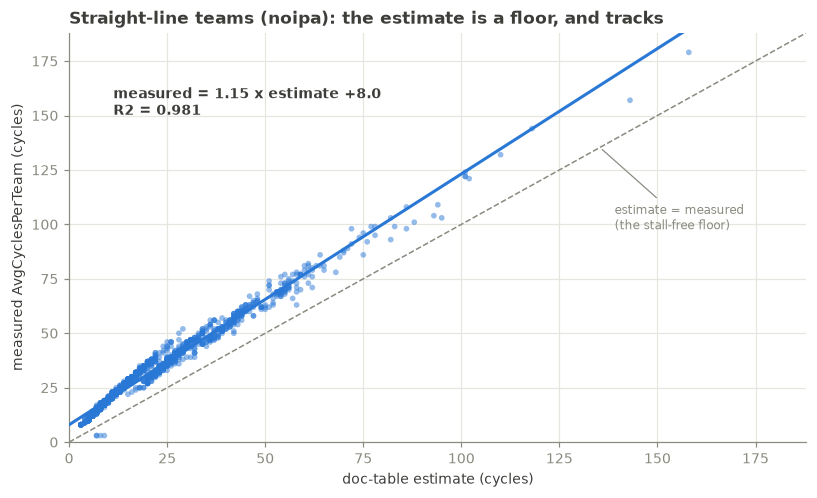

In [12]:
fit_sl = FITS[(P.name, "straight")]
SL = P.cls == "straight"
fig, ax = plt.subplots()
e, y = P.est[SL], P.meas[SL]
lim = max(e.max(), y.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.annotate("estimate = measured\n(the stall-free floor)", xy=(lim*0.72, lim*0.72),
            xytext=(lim*0.74, lim*0.52), color=MUTED, fontsize=8,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.scatter(e, y, s=14, color=C_STRAIGHT, alpha=0.5, edgecolor="none", zorder=2)
xs = np.linspace(0, lim, 2)
ax.plot(xs, fit_sl.beta[0]*xs + fit_sl.beta[1], color=C_STRAIGHT, lw=2, zorder=3)
ax.annotate(f"measured = {fit_sl.beta[0]:.2f} x estimate {fit_sl.beta[1]:+.1f}\nR2 = {fit_sl.r2:.3f}",
            xy=(lim*0.06, lim*0.80), color=INK, fontsize=9, fontweight="bold")
ax.set(xlabel="doc-table estimate (cycles)", ylabel="measured AvgCyclesPerTeam (cycles)",
       xlim=(0, lim), ylim=(0, lim),
       title=f"Straight-line teams ({P.name}): the estimate is a floor, and tracks")
plt.tight_layout(); plt.show()

**Reading it.** Points above the dashed line respect the floor. The distance to the
line is what the table does not explain: a fixed part (the intercept, section 7) and
a proportional part (the slope above 1, section 8). Straight-line teams are the
same code in both builds (section 2), so the two verdicts should agree; only the
primary build is drawn.

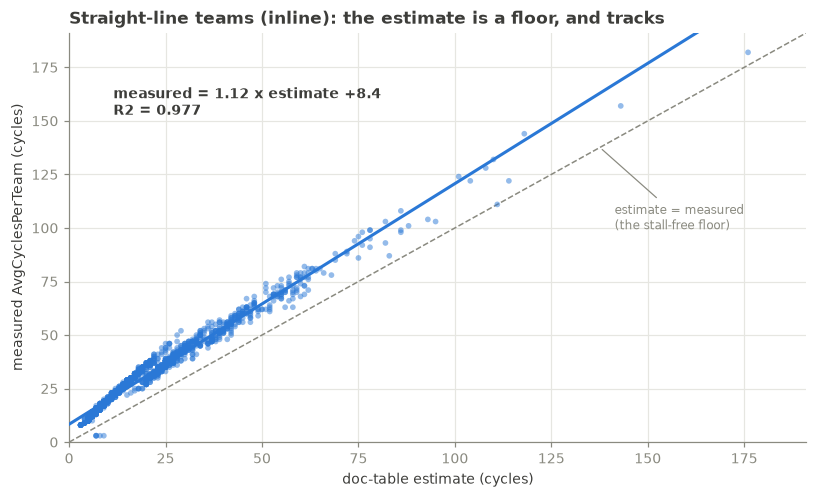

In [13]:
fit_sl = FITS[(S.name, "straight")]
SL = S.cls == "straight"
fig, ax = plt.subplots()
e, y = S.est[SL], S.meas[SL]
lim = max(e.max(), y.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.annotate("estimate = measured\n(the stall-free floor)", xy=(lim*0.72, lim*0.72),
            xytext=(lim*0.74, lim*0.52), color=MUTED, fontsize=8,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.scatter(e, y, s=14, color=C_STRAIGHT, alpha=0.5, edgecolor="none", zorder=2)
xs = np.linspace(0, lim, 2)
ax.plot(xs, fit_sl.beta[0]*xs + fit_sl.beta[1], color=C_STRAIGHT, lw=2, zorder=3)
ax.annotate(f"measured = {fit_sl.beta[0]:.2f} x estimate {fit_sl.beta[1]:+.1f}\nR2 = {fit_sl.r2:.3f}",
            xy=(lim*0.06, lim*0.80), color=INK, fontsize=9, fontweight="bold")
ax.set(xlabel="doc-table estimate (cycles)", ylabel="measured AvgCyclesPerTeam (cycles)",
       xlim=(0, lim), ylim=(0, lim),
       title=f"Straight-line teams ({S.name}): the estimate is a floor, and tracks")
plt.tight_layout(); plt.show()

## 5. Teams with branches in their own slice

**Question.** What happens to the estimate when the slice contains branches?

**Hypothesis H3.** *A branch lets the core skip instructions that the static sum
still counts, so the estimate exceeds the measurement.* By the table in the
introduction, a floor violation can only come from that or from an over-priced
instruction (H3c below); stalls, probes and callees cannot produce it.

**Test.** Calls are kept out (class "branches, no call"), so that the opposite
error of H4 cannot mask this one. Then: (a) floor-violation rate of the class
against the straight-line rate; (b) the same rate as a function of how many
branches a team has; (c) a plot of estimate against measurement for all classes.

**If H3 is true:** the violation rate is far above the straight-line rate and
grows with the number of branches. **If false:** branch teams respect the floor
like straight-line teams do.

Criterion: violation rate above 5% and at least ten times the straight-line rate.
A rejection here does not mean no code is skipped. It means the skipped code is
too small to push the estimate past the measurement; the estimate/measured ratio
printed next to it shows how much of the margin was used.

In [14]:
for b in B.values():
    f = report(b, "branch")
    f0 = FITS.get((b.name, "straight"))
    if f is None or f0 is None:
        verdict("H3", b.name, None, "too few teams with branches and no call")
    else:
        verdict("H3", b.name, f.viol > 0.05 and f.viol > 10 * f0.viol,
                f"floor violated on {100*f.viol:.1f}% of branch teams against {100*f0.viol:.1f}% "
                f"of straight-line teams; estimate/measured {f.ratio:.2f} against {f0.ratio:.2f}")
    print()

inline  branches, no call  (1232 teams)
  fit            : measured = 0.557 x estimate +19.2   R2 = 0.5535   MAE = 58.36 cycles
  floor violated : 641/1232 = 52.0%   (estimate > measured)
  estimate/measured : median 1.02     measured: median 76 cycles
>>> H3 [inline]: HOLDS -- floor violated on 52.0% of branch teams against 0.2% of straight-line teams; estimate/measured 1.02 against 0.54

noipa   branches, no call  (303 teams)
  fit            : measured = 1.217 x estimate +5.6   R2 = 0.9631   MAE = 1.90 cycles
  floor violated : 0/303 = 0.0%   (estimate > measured)
  estimate/measured : median 0.62     measured: median 25 cycles
>>> H3 [noipa]: REJECTED -- floor violated on 0.0% of branch teams against 0.2% of straight-line teams; estimate/measured 0.62 against 0.54



In [15]:
# Floor violation against the number of branches in the slice (call teams excluded).
bins = [0, 1, 2, 3, 5, 9, 17, 10**6]
for b in B.values():
    nbr = b.count(BRANCHES)
    keep = b.cls != "call"
    viol = b.est > b.meas
    print(f"{b.name}: teams without a call")
    print(f"  {'branches in slice':<20}{'teams':>8}{'instrs (median)':>18}{'floor violated':>16}{'median est/meas':>18}")
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = keep & (nbr >= lo) & (nbr < hi)
        if m.sum() == 0: continue
        lbl = f"{lo}" if hi == lo + 1 else f"{lo}-{hi-1}" if hi < 10**6 else f"{lo}+"
        print(f"  {lbl:<20}{m.sum():>8}{np.median(b.nins[m]):>18.0f}{100*viol[m].mean():>15.1f}%"
              f"{np.median(b.est[m]/np.maximum(b.meas[m], 1e-9)):>18.2f}")
    print()

inline: teams without a call
  branches in slice      teams   instrs (median)  floor violated   median est/meas
  0                       2028                14            0.2%              0.54
  1                        410                18           21.2%              0.70
  2                        125                28           22.4%              0.78
  3-4                       73               139           30.1%              0.93
  5-8                      320               131           73.1%              1.61
  9-16                     253               268           88.5%              1.90
  17+                       51               445           90.2%              1.97

noipa: teams without a call
  branches in slice      teams   instrs (median)  floor violated   median est/meas
  0                       1996                14            0.2%              0.54
  1                        234                14            0.0%              0.61
  2                         5

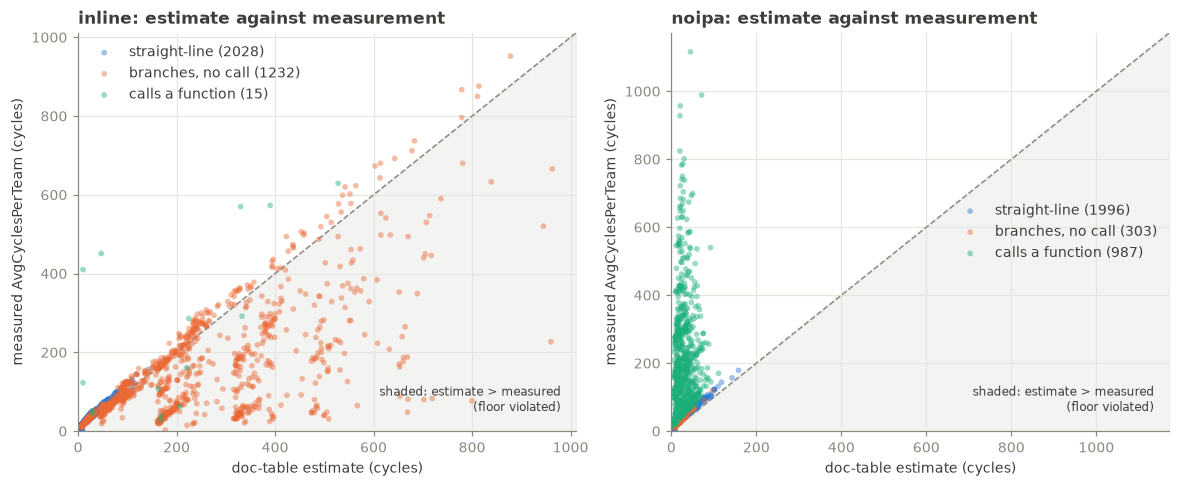

In [16]:
fig, axes = plt.subplots(1, len(B), figsize=(5.4 * len(B), 4.5), squeeze=False)
for ax, b in zip(axes[0], B.values()):
    lim = max(b.est.max(), b.meas.max()) * 1.05
    ax.fill_between([0, lim], [0, 0], [0, lim], color=MUTED, alpha=0.10, zorder=0)
    ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
    for c in CLASSES:
        m = b.cls == c
        if m.any():
            ax.scatter(b.est[m], b.meas[m], s=14, color=CLASS_COLOR[c], alpha=0.45,
                       edgecolor="none", label=f"{CLASS_LABEL[c]} ({m.sum()})", zorder=2)
    ax.annotate("shaded: estimate > measured\n(floor violated)", xy=(0.97, 0.04),
                xycoords="axes fraction", ha="right", va="bottom", color=INK, fontsize=8)
    ax.set(xlabel="doc-table estimate (cycles)", ylabel="measured AvgCyclesPerTeam (cycles)",
           xlim=(0, lim), ylim=(0, lim), title=f"{b.name}: estimate against measurement")
    ax.legend(loc="center right" if b.est.max() < 0.5 * lim else "upper left")
plt.tight_layout(); plt.show()

**Reading it.** Same teams, same core, two builds. In `inline`, the teams with
branches spread into the shaded region: the estimate charges for code that did not
run. In `noipa`, the few teams that still have branches stay above the diagonal,
and the teams that call a function rise far above it (section 6).

The branch-count table explains why the two builds disagree on H3. <mark style="background-color: #f1f1a6"> In `noipa` a
team has at most a few branches and stays small; the inventory in `results/`
reports that these branches jump forward over three to five instructions.That is
less than the fixed per-team cost of section 7, so the estimate over-counts
(its ratio to the measurement is above the straight-line one) without ever passing
the measurement.</mark> In `inline` the violation rate climbs with the number of
branches, and so does the size of the slice: the teams with many branches are an
order of magnitude larger. That points at *what* the branches belong to, which is
the next hypothesis.

### 5.1 Where the skipped code comes from

**Hypothesis H3b.** <mark style="background-color: #f1f1a6"> *The over-count comes from library bodies inlined into the
team,</mark>  not from the branches of the TPG's own operations.*

**Test.** This needs both builds. Take the branch teams of the first build and
split them by the class of the same team in the second build:  <mark style="background-color: #f1f1a6"> still "branch" there
means the branches are the team's own</mark> ; "call" there means the branches arrived
with an inlined function body.

**If H3b is true:** the floor violations are concentrated in the group whose twin
is a call team, and the group whose twin is still a branch team respects the floor.
**If false:** both groups violate alike.

Criterion: the first group's violation rate is above 5% and the second's is below 1%.

In [17]:
if not PAIR:
    verdict("H3b", "paired", None, "needs two builds that share teams")
else:
    a, b, pa, pb = PAIR["a"], PAIR["b"], PAIR["pa"], PAIR["pb"]
    src = a.cls[pa] == "branch"
    print(f"Teams that are 'branches, no call' in {a.name}, by their class in {b.name}:\n")
    print(f"  {'class in ' + b.name:<22}{'teams':>7}{'instrs in ' + a.name:>18}{'branches':>10}"
          f"{'floor violated':>16}{'median est/meas':>17}")
    nbr = a.count(BRANCHES)[pa]
    rate = {}
    for c in CLASSES:
        m = src & (b.cls[pb] == c)
        if m.sum() == 0: continue
        e, y = a.est[pa][m], a.meas[pa][m]
        rate[c] = (float((e > y).mean()), int(m.sum()))
        print(f"  {CLASS_LABEL[c]:<22}{m.sum():>7}{np.median(a.nins[pa][m]):>18.0f}{np.median(nbr[m]):>10.0f}"
              f"{100*rate[c][0]:>15.1f}%{np.median(e/np.maximum(y, 1e-9)):>17.2f}")
    print()
    if "call" not in rate or "branch" not in rate:
        verdict("H3b", "paired", None, "one of the two groups is empty")
    else:
        verdict("H3b", "paired", rate["call"][0] > 0.05 and rate["branch"][0] < 0.01,
                f"floor violated on {100*rate['call'][0]:.1f}% of the {rate['call'][1]} teams whose branches "
                f"come from an inlined function, and on {100*rate['branch'][0]:.1f}% of the "
                f"{rate['branch'][1]} teams whose branches are their own")

Teams that are 'branches, no call' in inline, by their class in noipa:

  class in noipa          teams  instrs in inline  branches  floor violated  median est/meas
  straight-line               2                58         2          100.0%             1.06
  branches, no call         303                16         1            0.0%             0.62
  calls a function          927               141         5           68.9%             1.26

>>> H3b [paired]: HOLDS -- floor violated on 68.9% of the 927 teams whose branches come from an inlined function, and on 0.0% of the 303 teams whose branches are their own


### 5.2 Is it skipped code, or an over-priced `div`?

A floor violation has a second possible cause: an instruction priced too high. The
table charges `div` its worst case of 35 cycles, while the manual's range starts at
3, and `div` only appears where a divide routine was inlined.

**Hypothesis H3c.** *The over-estimate is only `div` being priced at 35 cycles; no
code is skipped.*

**Test.** On the teams with branches and no call: (a) re-price `div` from 35 down
to 1 cycle and watch the violation rate; (b) compare teams with and without a
`div`; (c) for each team with a `div`, compute the cycles the measurement leaves
for it, (measured - estimate of everything else) / number of divs.

**If H3c is true:** a cheap `div` brings the violation rate down to the
straight-line level, teams without a `div` do not violate, and the cycles left per
`div` fall inside the manual's 3 to 35 range. **If false:** violations survive a
1-cycle `div`, and the cycles left per `div` are negative for many teams, meaning
the other instructions alone already exceed the measurement, which no price for
`div` can repair.

Criterion: fewer than 5% of the teams still violate with `div` priced at 1 cycle.
A build with no `div` in any team slice cannot test this and says so.

In [18]:
for b in B.values():
    nd_all = b.count(DIVS)
    print(f"{b.name}: teams containing a div/rem in their slice: {(nd_all > 0).sum()}"
          + "".join(f"   {CLASS_LABEL[c]}: {((nd_all > 0) & (b.cls == c)).sum()}" for c in CLASSES))
    if (nd_all > 0).sum() == 0:
        verdict("H3c", b.name, None,
                "no div in any team slice: the divides are behind a call in this build")
        print(); continue

    sub = b.cls == "branch"
    y_s, nd_s = b.meas[sub], nd_all[sub]
    base = b.est[sub] - sum(COSTS.get(d, 1) * b.count({d})[sub] for d in DIVS)  # all but the divs
    print(f"  on the {sub.sum()} teams with branches and no call:\n")
    print(f"  (a) {'div cost':>9}{'floor violated':>16}{'median est/meas':>18}")
    v = {}
    for d in (35, 20, 10, 5, 3, 1):
        e_ = base + d * nd_s
        v[d] = float((e_ > y_s).mean())
        print(f"      {d:>9}{100*v[d]:>15.1f}%{np.median(e_/np.maximum(y_s, 1)):>18.2f}")

    print("\n  (b) with and without a div, at div = 35 and div = 3:")
    for d in (35, 3):
        e_ = base + d * nd_s
        for lbl, m in (("no div", nd_s == 0), ("has div", nd_s > 0)):
            if m.sum():
                print(f"      div={d:<3} {lbl:<8}{m.sum():>5} teams   floor violated "
                      f"{100*(e_[m] > y_s[m]).mean():>5.1f}%   median est/meas "
                      f"{np.median(e_[m]/np.maximum(y_s[m], 1)):.2f}")

    m = nd_s > 0
    implied = (y_s[m] - base[m]) / nd_s[m]
    neg = float((implied < 0).mean())
    print(f"\n  (c) cycles the measurement leaves for each div: median {np.median(implied):.1f}"
          f"   p10 {np.percentile(implied, 10):.1f}   p90 {np.percentile(implied, 90):.1f}"
          f"   negative for {100*neg:.0f}% of the {m.sum()} teams\n")
    verdict("H3c", b.name, v[1] < 0.05,
            f"pricing div at 1 instead of 35 moves the violation rate {100*v[35]:.1f}% -> {100*v[1]:.1f}%; "
            f"the non-div instructions alone exceed the measurement on {100*neg:.0f}% of teams with a div")
    print()

inline: teams containing a div/rem in their slice: 889   straight-line: 0   branches, no call: 879   calls a function: 10
  on the 1232 teams with branches and no call:

  (a)  div cost  floor violated   median est/meas
             35           52.0%              1.02
             20           38.8%              0.87
             10           37.9%              0.82
              5           37.3%              0.80
              3           37.1%              0.80
              1           36.9%              0.79

  (b) with and without a div, at div = 35 and div = 3:
      div=35  no div    353 teams   floor violated   0.0%   median est/meas 0.63
      div=35  has div   879 teams   floor violated  72.9%   median est/meas 1.33
      div=3   no div    353 teams   floor violated   0.0%   median est/meas 0.63
      div=3   has div   879 teams   floor violated  52.0%   median est/meas 1.06

  (c) cycles the measurement leaves for each div: median -5.5   p10 -106.0   p90 46.0   negative fo

**Reading it.** The drop in the violation rate between `div` = 35 and `div` = 1 is
the part of the over-estimate that the price of `div` can explain; what remains at
1 cycle is skipped code. The share of teams with a *negative* number of cycles
left per `div` is the cleanest figure: for those, the price of `div` is irrelevant.

Test (b) cannot discriminate on this data, and should not be read as support for
H3c: a `div` is in the slice only where a divide routine was inlined, so "has a
div" also means "has a large body with paths that are skipped", the divide's own
guard among them. For the same reason `div` never appears in a straight-line team,
its cost and the skipped code cannot be separated by a fit, and `DIV_CYCLES`
cannot be calibrated from the `inline` build. The `noipa` build
offers a cleaner route: there the divide sits in `protected_fixedpt_div_32`, whose
cost per call is measured in section 6.

## 6. Teams that call a function

**Question.** What happens to the estimate when the team's work is done by a
function outside its slice?

**Hypothesis H4.** *A call is charged the 2 cycles of its `jal`, while the
measurement includes the whole callee,  <mark style="background-color: #6aff6d"> so the estimate is far below the
measurement, and the missing cycles are explained by which functions are called.*</mark>

**Test.** On call teams: (a) the estimate/measured ratio (-> 0) and the floor-violation
rate (-> 0 et diagonale haute) against the straight-line ones; (b) regress the unexplained cycles
(measured - estimate) on the number of calls to each function, which yields one
cost per function; (c) on teams with exactly one call, the spread of the
unexplained cycles per function.

**If H4 is true:** the floor is never violated, the ratio is well below the
straight-line ratio, and the per-function costs are positive and explain most of
the gap. **If false:** call teams look like straight-line teams, or the gap is
unrelated to the functions called.

Criterion: floor violated on fewer than 1% of call teams, ratio below the
straight-line ratio, and the per-function regression reaching R2 above 0.5.

In [19]:
for b in B.values():
    f = report(b, "call")
    f0 = FITS.get((b.name, "straight"))
    mask = b.cls == "call"
    if f is None or f0 is None or mask.sum() < 30:
        verdict("H4", b.name, None,
                f"{mask.sum()} call teams: the functions are inlined in this build")
        print(); continue

    rows_c = [r for r in b.rows if r.cls == "call"]
    callees = sorted({op for r in rows_c for op in r.ops if mnem(op) in CALLS})
    X = np.array([[r.ops.get(c, 0) for c in callees] for r in rows_c], float)
    gap = b.meas[mask] - b.est[mask]
    g = ols(X, gap, callees)
    one = X.sum(axis=1) == 1
    print(f"\n  (b) unexplained cycles = sum(cost x calls) + {g.beta[-1]:.1f}     R2 = {g.r2:.3f}\n")
    print(f"      {'function':<28}{'cycles/call':>12}{'calls':>7}{'teams':>7}"
          f"   | teams with this single call: {'n':>4}{'median':>8}{'p10':>7}{'p90':>7}")
    for j, c in enumerate(callees):
        s = one & (X[:, j] == 1)
        tail = (f"{s.sum():>4}{np.median(gap[s]):>8.0f}{np.percentile(gap[s], 10):>7.0f}"
                f"{np.percentile(gap[s], 90):>7.0f}") if s.sum() >= 5 else f"{s.sum():>4}"
        print(f"      {c[len('jal_'):] if c.startswith('jal_') else c:<28}{g.beta[j]:>12.1f}"
              f"{X[:, j].sum():>7.0f}{(X[:, j] > 0).sum():>7}   | {'':<29}{tail}")
    print()
    verdict("H4", b.name, f.viol < 0.01 and f.ratio < f0.ratio and g.r2 > 0.5,
            f"estimate/measured {f.ratio:.2f} on call teams against {f0.ratio:.2f} on straight-line "
            f"teams, floor violated {100*f.viol:.1f}%; one cost per function explains "
            f"{100*g.r2:.0f}% of the missing cycles")
    print()

inline  calls a function  (15 teams)
  fit            : measured = 0.843 x estimate +94.8   R2 = 0.3537   MAE = 144.12 cycles
  floor violated : 6/15 = 40.0%   (estimate > measured)
  estimate/measured : median 0.79     measured: median 161 cycles
>>> H4 [inline]: NOT TESTABLE -- 15 call teams: the functions are inlined in this build

noipa   calls a function  (987 teams)
  fit            : measured = 1.662 x estimate +135.2   R2 = 0.0308   MAE = 112.49 cycles
  floor violated : 0/987 = 0.0%   (estimate > measured)
  estimate/measured : median 0.21     measured: median 132 cycles

  (b) unexplained cycles = sum(cost x calls) + 16.8     R2 = 0.767

      function                     cycles/call  calls  teams   | teams with this single call:    n  median    p10    p90
      fixedpt_cos                         96.5    125    104   |                                28     120    112    128
      fixedpt_exp_wdiv32                  51.0    931    577   |                               208    

**Reading it.** The "cycles/call" column is what the model would have to add per
`jal` to that function. Compare it with the 2 cycles the estimate charges.

<mark style="background-color: #f1f1a6"> The right-hand columns show why one number per function is not enough. </mark>Among teams
that make the same single call, the unexplained cycles vary widely between the
10th and 90th percentile. The cost of these functions depends on the argument:
`exp` returns at once for a zero or out-of-range argument, `ln` for `x <= 0`, the
protected divide for a small divisor. A `jal` count cannot see that.
`analysis/static_args.py` recovers the part of it that is known at compile time.

This is the same information as section 5, read from the other side. In `inline`
the body is in the slice and the estimate counts all of its paths; in `noipa` the
body is out of the slice and the estimate counts none of it. Neither build gives
the static sum the executed path.

## 7. The instrumentation cost

Sections 7 to 9 use one build (noipa) and, where they need teams, only its
straight-line teams: those are the same code in both builds, and they are the only
teams on which the estimate is a valid floor.

**Question.** <mark style="background-color: #f1f1a6"> The fit of section 4 has a positive intercept: every team costs a
few cycles more than its instructions. Is that the measurement probe?</mark>

**Hypothesis H5.** *Instrumenting the teams adds a real cost, paid once per team
visited.*

**Test.** `latencies.json` measures the same TPG under two instrumentation modes
(parsed in `analysis/disassembler.py`, stored as `ClassLatencyPair` in
`classes/tpg.py`): `tpg_only`, where only the graph is instrumented, and
`tpg_teams`, where every team is instrumented as well. Same program, same input,
same core. Their difference is a measured quantity. Regress it on the number of
teams the traversal visits: the slope is the cost of one team probe.

**If H5 is true:** <mark style="background-color: #f1f1a6"> the difference is positive for practically every traversal and
grows linearly with the number of teams visited.</mark> **If false:** it scatters around
zero, with about half the traversals negative.

Criterion: fewer than 5% of traversals have a negative difference, and the slope
is positive.



In [20]:
overcost, pct, nteams, tpg_only = [], [], [], []
for tpg in P.db.tpgs.values():
    for cid, pair in tpg.class_latencies.get(UARCH, {}).items():
        visited = tpg.traversals.get(cid, [])
        if visited:
            overcost.append(pair.overcost)     # tpg_teams - tpg_only
            pct.append(pair.overcost_pct)
            nteams.append(len(visited))
            tpg_only.append(pair.tpg_only)
overcost, pct, nteams, tpg_only = (np.array(a, float) for a in (overcost, pct, nteams, tpg_only))

print(f"{P.name}: traversals measured under both modes: {len(overcost)}\n")
print("overcost = tpg_teams - tpg_only")
print(f"  median {np.median(overcost):7.1f} cycles   mean {overcost.mean():7.1f}")
print(f"  as % of tpg_only: median {np.median(pct):.2f}%  "
      f"(p10 {np.percentile(pct, 10):.2f}, p90 {np.percentile(pct, 90):.2f})")
print(f"  negative overcosts: {100*(overcost < 0).mean():.1f}%   (free probes would give about 50%)")

# The cost of ONE probe is a slope, not a division: regressing against the team
# count separates the per-probe cost from any fixed per-traversal cost.
f_probe = ols(nteams, overcost, ["n_teams"])
print(f"\ncost of one team probe, by regression on the teams visited:\n  {f_probe}")
print(f"  -> one team probe      : {f_probe.beta[0]:.2f} cycles")
print(f"  -> fixed per traversal : {f_probe.beta[1]:+.2f} cycles")

f_both = ols(np.c_[nteams, tpg_only], overcost, ["n_teams", "tpg_only"])
print(f"\ndoes it also grow with the work the traversal does?\n  {f_both}")
print(f"  -> {f_both.beta[1]:+.4f} cycles of overcost per cycle of tpg_only latency\n")
verdict("H5", P.name, (overcost < 0).mean() < 0.05 and f_probe.beta[0] > 0,
        f"{100*(overcost < 0).mean():.1f}% of {len(overcost)} traversals are faster with probes; "
        f"{f_probe.beta[0]:.1f} cycles per team visited (R2 = {f_probe.r2:.2f}), "
        f"median {np.median(pct):.0f}% of the uninstrumented latency")

noipa: traversals measured under both modes: 872

overcost = tpg_teams - tpg_only
  median    89.0 cycles   mean    95.3
  as % of tpg_only: median 15.82%  (p10 5.98, p90 34.49)
  negative overcosts: 0.0%   (free probes would give about 50%)

cost of one team probe, by regression on the teams visited:
  n=872  n_teams=+14.109  const=+6.06   R2=0.8499  MAE=12.03 cyc
  -> one team probe      : 14.11 cycles
  -> fixed per traversal : +6.06 cycles

does it also grow with the work the traversal does?
  n=872  n_teams=+16.033  tpg_only=-0.014  const=+4.16   R2=0.8773  MAE=11.10 cyc   [!] collinear, read coefficients with care
  -> -0.0137 cycles of overcost per cycle of tpg_only latency

>>> H5 [noipa]: HOLDS -- 0.0% of 872 traversals are faster with probes; 14.1 cycles per team visited (R2 = 0.85), median 16% of the uninstrumented latency


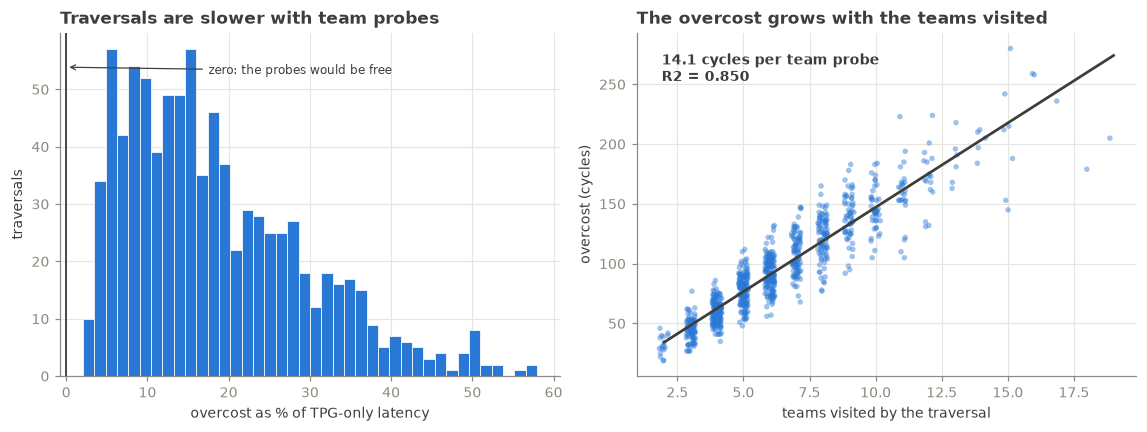

In [88]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax1.hist(pct, bins=40, color=C_STRAIGHT, edgecolor="white", linewidth=0.5)
ax1.axvline(0, color=INK, lw=1.2)
ax1.annotate("zero: the probes would be free", xy=(0, ax1.get_ylim()[1]*0.9),
             xytext=(np.percentile(pct, 55), ax1.get_ylim()[1]*0.88), color=INK,
             fontsize=8, arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))
ax1.set(xlabel="overcost as % of TPG-only latency", ylabel="traversals",
        title="Traversals are slower with team probes")

jit = nteams + np.random.default_rng(0).uniform(-0.18, 0.18, len(nteams))
ax2.scatter(jit, overcost, s=13, color=C_STRAIGHT, alpha=0.45, edgecolor="none")
xs = np.array([nteams.min(), nteams.max()])
ax2.plot(xs, f_probe.beta[0]*xs + f_probe.beta[1], color=INK, lw=1.8)
ax2.annotate(f"{f_probe.beta[0]:.1f} cycles per team probe\nR2 = {f_probe.r2:.3f}",
             xy=(0.05, 0.86), xycoords="axes fraction", color=INK, fontsize=9, fontweight="bold")
ax2.set(xlabel="teams visited by the traversal", ylabel="overcost (cycles)",
        title="The overcost grows with the teams visited")
plt.tight_layout(); plt.show()

### 7.1 Is the per-team constant of section 4 that probe?

**Hypothesis H6.** *The intercept of the straight-line fit (cycles a team costs
beyond its instructions) equals the cost of one team probe.*

**Test.** Compare the two numbers. Then look at the smallest straight-line teams,
which need no model: a team of k one-cycle instructions cannot legitimately report
more than k cycles plus whatever the measurement adds *inside* the window it times.

**If H6 is true:** the probe cost and the intercept agree, and the smallest teams
report their instruction count plus that same amount. **If false:** they differ,
and the difference is probe cost that lands outside the timed window (visible in
the whole-TPG total only), or a team entry cost that is not the probe at all.

Criterion: the two numbers agree within 25%.

In [89]:
probe, const = f_probe.beta[0], fit_sl.beta[1]
print(f"measured cost of one team probe (section 7 slope) : {probe:6.2f} cycles")
print(f"per-team constant of the straight-line fit        : {const:6.2f} cycles")
print(f"ratio                                             : {probe/const:6.2f}x\n")

tiny = [(r.n, e, r.meas) for r, e in zip(P.rows, P.est) if r.cls == "straight" and r.n <= 7]
print("smallest straight-line teams:")
print(f"  {'instrs':>7}{'teams':>7}{'estimate':>10}{'measured':>10}{'min':>6}{'measured - estimate':>21}")
offs = []
for k in sorted({n for n, _, _ in tiny}):
    g = [(e, y) for n, e, y in tiny if n == k]
    est_k, mea_k = np.mean([e for e, _ in g]), np.mean([y for _, y in g])
    offs.append(mea_k - est_k)
    print(f"  {k:>7}{len(g):>7}{est_k:>10.1f}{mea_k:>10.1f}{min(y for _, y in g):>6.0f}{mea_k - est_k:>21.1f}")
inside = float(np.median(offs)) if offs else float("nan")
print(f"\n  -> about {inside:.1f} cycles per team sit inside the timed window; the probe costs {probe:.1f},"
      f"\n     so about {probe - inside:.1f} cycles of it are spent outside the window.\n")
verdict("H6", P.name, 0.8 <= probe / const <= 1.25,
        f"probe {probe:.1f} cycles against a per-team constant of {const:.1f} "
        f"({probe/const:.1f}x); the smallest teams carry {inside:.1f} cycles beyond their instructions")

measured cost of one team probe (section 7 slope) :  14.11 cycles
per-team constant of the straight-line fit        :   7.99 cycles
ratio                                             :   1.77x

smallest straight-line teams:
   instrs  teams  estimate  measured   min  measured - estimate
        3     17       3.0       8.0     8                  5.0
        4     14       4.0       9.4     9                  5.4
        5     61       5.0      10.6    10                  5.6
        6     87       6.0      13.0    12                  7.0
        7    172       7.0      14.1     3                  7.1

  -> about 5.6 cycles per team sit inside the timed window; the probe costs 14.1,
     so about 8.5 cycles of it are spent outside the window.

>>> H6 [noipa]: REJECTED -- probe 14.1 cycles against a per-team constant of 8.0 (1.8x); the smallest teams carry 5.6 cycles beyond their instructions


**Reading it.** H5 says the probe is real. H6 asks whether it is the constant in
the team-level fit, and the smallest teams settle how much of it is: only the part
that falls inside the window a team's own counter delta covers.

What that inside part *is* stays open, because two explanations predict the same
numbers: (a) probe instructions and counter-read asymmetry inside the window, an
artefact to subtract; (b) genuine team entry and exit work such as the jump into
the team, a real cost to keep. Both are "a fixed cost once per team". One run with
a deliberately heavier probe (N extra `nop`s) separates them: if `AvgCyclesPerTeam`
grows by N, the window includes the probe and the constant can be calibrated and
subtracted.

## 8. The proportional gap above the floor

**Question.** Besides the constant, the straight-line fit has a slope above 1: the
measurement grows faster than the estimate. What is that?

**Hypothesis H7.** *It is the manual's load-use penalty: one extra cycle when an
instruction uses the result of the load just before it.* The table leaves hazards
out, so they are the first candidate.

**Test.** On straight-line teams, fit measured on the estimate alone, then on the
estimate plus the number of distance-1 load-use hazards in the team.

**If H7 is true:** adding the hazard count brings the estimate's coefficient to
about 1, and the hazard coefficient is about 1 cycle. **If false:** the estimate's
coefficient stays where it was.

Criterion: the estimate's coefficient ends within 0.05 of 1 and closer to 1 than
it started.

In [90]:
e, y = P.est[SL], P.meas[SL]
gap = y - e                                   # cycles the manual's table does not explain
print(f"{P.name}: {SL.sum()} straight-line teams")
print(f"  mean measured {y.mean():.2f}   mean estimate {e.mean():.2f}   "
      f"mean gap {gap.mean():.2f} cycles ({100*gap.mean()/y.mean():.1f}% of measured)")
print(f"  gap: median {np.median(gap):+.1f}   p10 {np.percentile(gap, 10):+.1f}   p90 {np.percentile(gap, 90):+.1f} cycles\n")

f_prop = ols(e, y, ["estimate"])
print(f"estimate alone            : measured = {f_prop.beta[0]:.3f} x estimate {f_prop.beta[1]:+.2f}")
print(f"    -> proportional part: {100*(f_prop.beta[0]-1):+.1f}% on every cycle the table predicts")
print(f"    -> fixed part       : {f_prop.beta[1]:+.2f} cycles per team\n")
f_haz = ols(np.c_[e, P.lu[SL]], y, ["estimate", "load_use"])
print(f"estimate + load-use count : {f_haz}\n")
verdict("H7", P.name,
        abs(f_haz.beta[0] - 1) < 0.05 and abs(f_haz.beta[0] - 1) < abs(f_prop.beta[0] - 1),
        f"the estimate's coefficient goes {f_prop.beta[0]:.3f} -> {f_haz.beta[0]:.3f} once load-use "
        f"hazards are charged, at {f_haz.beta[1]:.2f} cycles per hazard (manual: 1)")

noipa: 1996 straight-line teams
  mean measured 30.43   mean estimate 19.49   mean gap 10.94 cycles (36.0% of measured)
  gap: median +11.0   p10 +7.0   p90 +16.0 cycles

estimate alone            : measured = 1.152 x estimate +7.99
    -> proportional part: +15.2% on every cycle the table predicts
    -> fixed part       : +7.99 cycles per team

estimate + load-use count : n=1996  estimate=+1.007  load_use=+1.742  const=+4.99   R2=0.9905  MAE=1.16 cyc   [!] collinear, read coefficients with care

>>> H7 [noipa]: HOLDS -- the estimate's coefficient goes 1.152 -> 1.007 once load-use hazards are charged, at 1.74 cycles per hazard (manual: 1)


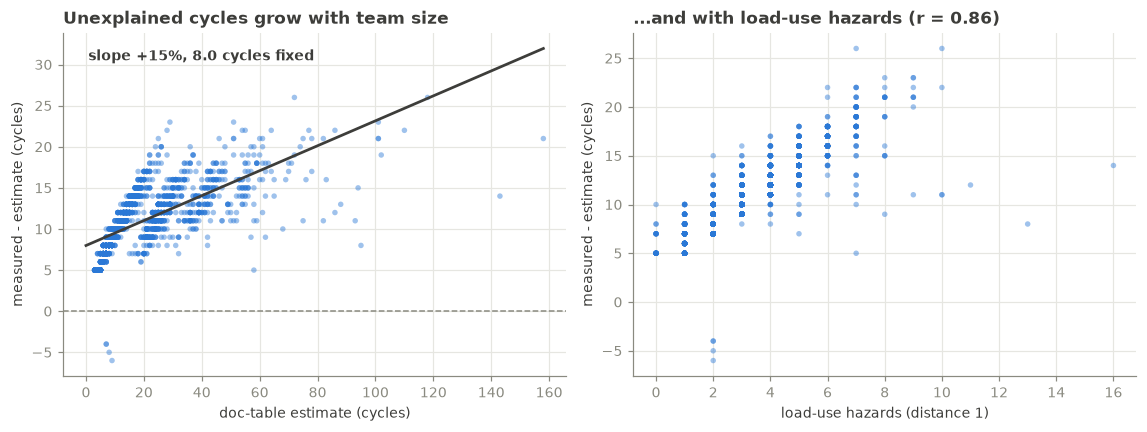

In [91]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax1.scatter(e, gap, s=13, color=C_STRAIGHT, alpha=0.45, edgecolor="none")
ax1.axhline(0, color=MUTED, lw=1, ls="--")
xs = np.linspace(0, e.max(), 2)
ax1.plot(xs, (f_prop.beta[0]-1)*xs + f_prop.beta[1], color=INK, lw=1.8)
ax1.annotate(f"slope {100*(f_prop.beta[0]-1):+.0f}%, {f_prop.beta[1]:.1f} cycles fixed",
             xy=(0.05, 0.92), xycoords="axes fraction", color=INK, fontsize=9, fontweight="bold")
ax1.set(xlabel="doc-table estimate (cycles)", ylabel="measured - estimate (cycles)",
        title="Unexplained cycles grow with team size")
ax2.scatter(P.lu[SL], gap, s=13, color=C_STRAIGHT, alpha=0.45, edgecolor="none")
ax2.set(xlabel="load-use hazards (distance 1)", ylabel="measured - estimate (cycles)",
        title=f"...and with load-use hazards (r = {np.corrcoef(P.lu[SL], gap)[0,1]:.2f})")
plt.tight_layout(); plt.show()

## 9. The costs the data itself would choose

**Question.** Sections 4 to 8 test the table as a whole. Taken row by row, are the
manual's costs the ones the measurements imply?

**Hypothesis H8.** *Solving for one cost per instruction group on straight-line
teams returns the manual's values.*

**Test.** Each team gives one equation: measured = sum(cost of group x count of
group) + constant. Least squares solves for the costs, in cycles, next to the
manual's.

**If H8 is true:** fitted and manual costs agree for the groups that are present
in the data. **If false:** they differ. There is a third outcome, and the cell
checks for it first: instruction counts and hazard counts rise together with team
size, and when they are too collinear (condition number above 30) the individual
coefficients trade off against each other. The fit as a whole is then sound, but
its rows are not measurements, and H8 is reported as not testable rather than
rejected.

Criterion: condition number at most 30, and every group with at least 0.5
instructions per team on average lands within 0.5 cycles of the manual.

In [92]:
def group_counts(r):
    c = {k: 0 for k in ("alu", "load", "store", "mul", "mulh")}
    for op, n in r.ops.items():
        m = mnem(op)
        if   m in LOADS:  c["load"]  += n
        elif m in STORES: c["store"] += n
        elif m in MULH:   c["mulh"]  += n
        elif m == "mul":  c["mul"]   += n
        else:             c["alu"]   += n
    return c

sl_rows = [r for r in P.rows if r.cls == "straight"]
G = [group_counts(r) for r in sl_rows]
X = np.array([[g["alu"], g["load"], g["store"], g["mul"], g["mulh"]] for g in G], float)
X = np.c_[X, P.lu[SL], np.array([r.alu_haz for r in sl_rows], float)]
names = ["ALU", "load", "store", "mul", "mulh*", "load-use haz", "alu-alu haz"]
doc   = [1, 1, 1, 1, 4, 1, 0]

f = ols(X, y, names)
print(f"{P.name}: {SL.sum()} straight-line teams   R2 = {f.r2:.4f}   MAE = {f.mae:.2f} cycles"
      f"   condition number = {f.cond:.0f}\n")
print(f"  {'group':<16}{'fitted':>9}{'manual':>8}{'mean/team':>12}")
print("  " + "-" * 45)
off = []
for nm, bta, d, col in zip(names, f.beta[:-1], doc, X.T):
    flag = ""
    if col.mean() >= 0.5 and abs(bta - d) > 0.5:
        off.append(nm); flag = "   <- differs from the manual"
    if bta < -0.05:
        flag = "   <- negative: not a cost, a collinearity artefact"
    print(f"  {nm:<16}{bta:>9.3f}{d:>8}{col.mean():>12.1f}{flag}")
print(f"  {'constant':<16}{f.beta[-1]:>9.3f}{'--':>8}\n")
if f.cond > 30:
    verdict("H8", P.name, None,
            f"condition number {f.cond:.0f}: the groups are collinear, so the rows cannot be read "
            f"one by one (the fit as a whole reaches R2 = {f.r2:.3f})")
else:
    verdict("H8", P.name, not off,
            "every well-represented group is within 0.5 cycles of the manual" if not off
            else "differs from the manual on: " + ", ".join(off))

noipa: 1996 straight-line teams   R2 = 0.9948   MAE = 0.75 cycles   condition number = 249

  group              fitted  manual   mean/team
  ---------------------------------------------
  ALU                 1.019       1         7.0
  load                1.817       1         5.1   <- differs from the manual
  store               1.802       1         3.5   <- differs from the manual
  mul                 1.407       1         1.7
  mulh*               5.179       4         0.6   <- differs from the manual
  load-use haz        0.332       1         3.3   <- differs from the manual
  alu-alu haz        -0.504       0         2.7   <- negative: not a cost, a collinearity artefact
  constant            2.765      --

>>> H8 [noipa]: NOT TESTABLE -- condition number 249: the groups are collinear, so the rows cannot be read one by one (the fit as a whole reaches R2 = 0.995)


## 10. Knobs to iterate on

**What this section does.** It tests no hypothesis. It sweeps the three rows of the
manual's table that depend on run-time state, to show how sensitive the fit is to
each, on every build.

Read the sweeps with sections 5 and 6 in mind. `div` and `branch` only occur in
teams whose estimate is not a floor in the first place, so the value that fits best
there compensates for skipped code and is not a calibration. The `mulh` sweep runs
on straight-line teams and is the only one on clean ground; how much it can say
depends on how often `mulh` occurs per team, which the cell prints.

In [93]:
def sweep(b, key_costs, mask, label):
    c = dict(COSTS); c.update(key_costs)
    e_ = np.array([estimate(r, c) for r in b.rows], float)[mask]
    y_ = b.meas[mask]
    f_ = ols(e_, y_, ["est"])
    print(f"    {label:<12} slope={f_.beta[0]:.3f}  R2={f_.r2:.4f}  "
          f"MAE={f_.mae:6.2f}  floor violated {100*(e_ > y_).mean():5.1f}%")

COND = ("beq", "bne", "blt", "bge", "bltu", "bgeu", "beqz", "bnez", "blez", "bgez", "bltz", "bgtz")
for b in B.values():
    br, sl = b.cls == "branch", b.cls == "straight"
    print(f"{b.name}")
    if (b.count(DIVS)[br] > 0).any():
        print(f"  DIV_CYCLES on the {br.sum()} teams with branches and no call (manual: 3 to 35)")
        for d in (3, 10, 20, 35):
            sweep(b, {k: d for k in DIVS}, br, f"div={d}")
    else:
        print("  DIV_CYCLES: no div in any team slice, nothing to sweep")
    if br.sum() >= 10:
        print(f"  BRANCH_CYCLES on the same teams (manual: 1 not taken, 3 taken)")
        for k in (1, 2, 3):
            sweep(b, {m: k for m in COND}, br, f"branch={k}")
    per_team = b.count(MULH)[sl].mean()
    print(f"  mulh/mulhu/mulhsu on the {sl.sum()} straight-line teams (manual: 4); "
          f"{per_team:.2f} occurrences per team")
    for k in (1, 2, 3, 4, 5, 6):
        sweep(b, {m: k for m in MULH}, sl, f"mulh={k}")
    print()

inline
  DIV_CYCLES on the 1232 teams with branches and no call (manual: 3 to 35)
    div=3        slope=0.675  R2=0.5710  MAE= 59.63  floor violated  37.1%
    div=10       slope=0.647  R2=0.5677  MAE= 59.20  floor violated  37.9%
    div=20       slope=0.608  R2=0.5624  MAE= 58.73  floor violated  38.8%
    div=35       slope=0.557  R2=0.5535  MAE= 58.36  floor violated  52.0%
  BRANCH_CYCLES on the same teams (manual: 1 not taken, 3 taken)
    branch=1     slope=0.557  R2=0.5535  MAE= 58.36  floor violated  52.0%
    branch=2     slope=0.541  R2=0.5497  MAE= 58.70  floor violated  55.1%
    branch=3     slope=0.527  R2=0.5460  MAE= 59.03  floor violated  57.9%
  mulh/mulhu/mulhsu on the 2028 straight-line teams (manual: 4); 0.56 occurrences per team
    mulh=1       slope=1.367  R2=0.9875  MAE=  1.36  floor violated   0.2%
    mulh=2       slope=1.276  R2=0.9846  MAE=  1.59  floor violated   0.2%
    mulh=3       slope=1.196  R2=0.9812  MAE=  1.83  floor violated   0.2%
    mulh=4  

## Summary

The table below is printed from the verdicts recorded above, so it always matches
the databases the notebook was last run on.

In [23]:
order = {h: i for i, h in enumerate(("H1", "H2", "H3", "H3b", "H3c", "H4", "H5", "H6", "H7", "H8"))}
CLAIM = {
    "H1":  "the build moves a team's code, not its work",
    "H2":  "no control flow: the estimate is a floor and tracks",
    "H3":  "branches in the slice: the estimate counts code that did not run",
    "H3b": "...and that code is inlined library bodies",
    "H3c": "...or it is only div priced at 35 cycles",
    "H4":  "calls: the estimate misses the callee's body",
    "H5":  "team probes add a real per-team cost",
    "H6":  "the per-team constant of the fit is that probe",
    "H7":  "the proportional gap is the load-use penalty",
    "H8":  "the manual's costs can be recovered row by row",
}
for h, scope, status, numbers in sorted(VERDICTS, key=lambda v: (order.get(v[0], 99), v[1])):
    print(f"{h:<4}{CLAIM.get(h, ''):<68}{scope:<8}{status}")
    print(f"      {numbers}\n")

H1  the build moves a team's code, not its work                         paired  HOLDS
      90.8% of 3275 pairs measure the same within 10% or 10 cycles (r = 0.980), while the static size of the 964 class-changing teams differs 7.0x

H2  no control flow: the estimate is a floor and tracks                 inline  HOLDS
      floor violated 0.2%, R2 = 0.977, measured = 1.12 x estimate +8.4

H2  no control flow: the estimate is a floor and tracks                 noipa   HOLDS
      floor violated 0.2%, R2 = 0.981, measured = 1.15 x estimate +8.0

H3  branches in the slice: the estimate counts code that did not run    inline  HOLDS
      floor violated on 52.0% of branch teams against 0.2% of straight-line teams; estimate/measured 1.02 against 0.54

H3  branches in the slice: the estimate counts code that did not run    noipa   REJECTED
      floor violated on 0.0% of branch teams against 0.2% of straight-line teams; estimate/measured 0.62 against 0.54

H3b ...and that code is inlined libr

**What the verdicts add up to.**

- **The model is sound where its assumption holds.** On straight-line code the
  estimate is a floor and tracks the measurement, in both builds (H2). What it
  leaves unexplained there is a per-team constant (H5, H6) and the load-use
  penalty (H7).
- **The class of a team is decided by the build.** The same team is "branchy" with
  a large slice in `inline` and a short "call" team in `noipa`, for the same
  measured latency (H1). Any statement about "branchy teams" has to say which build.
- **The static sum fails on library functions in both builds, in opposite
  directions.** Inlined, their body is counted in full although one path runs, and
  the floor breaks (H3, H3b); the price of `div` makes it worse but is not the
  cause (H3c). Called, their body is not counted at all, and the estimate falls far
  below the measurement (H4).
- **Branches of the TPG's own operations are harmless at this scale.** They skip a
  handful of instructions, less than the per-team constant.

**Where to go next**, in order of value:

1. **Give the model the executed path of the library functions.** Either dynamic
   instruction counts (per-basic-block instrumentation, or execution counts from
   the simulator), or a per-function cost in the `noipa` build that depends on the
   argument class from `analysis/static_args.py`. Section 6 shows a single cost per
   function leaves a wide spread.
2. **Calibrate the per-team constant.** One run with N `nop`s added inside the
   probe splits measurement artefact from genuine team entry cost. Until then the
   constant is absorbed by an intercept, which is fine for per-team prediction but
   over-counts when the teams of a traversal are summed.
3. **Exercise the cost table.** Straight-line teams are almost entirely one-cycle
   instructions, so the table's other rows are barely tested (H8). `noipa` makes
   one of them measurable: the divide now sits alone inside
   `protected_fixedpt_div_32`.